# 03 · End to End

**Goal:** run the extracted entries through matching's `decide()`, the same call the app makes, and see whether the right matters come out.

Notebooks 01 and 02 graded extraction against what is written on each page. This notebook checks the next step: once a handwritten sheet or a photographed note is turned into the shared table, does matching treat it like any other entry?

It only reads matching's saved models. Nothing is retrained, nothing is added to billing history (no `add_confirmed`), and nothing is saved to `matching/`.

| Input | Entries | Intended matter known for |
|---|---|---|
| Scanned sheets (HW-01 to HW-04) | 23 | entries with a written CMID, firm time, and clients that aren't in the firm |
| Notes with drawn columns | 10 | all of them |
| Free-text note photos | 11 | all of them (written from the firm's client list, as R. Patel) |

**Questions**
1. Do extracted entries run through matching as they are?
2. What does matching decide for each kind of input?
3. When the intended matter is known, does matching find it, and does it avoid matching clients that aren't the firm's?
4. How often does an automatic match still have hours to confirm?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
sys.path.insert(0, "../../matching/src")
from extract import extract
from intake import for_matching, timekeeper_table
from pipeline import decide, load_reference
from textract import load_pages

In [2]:
DATA_PATH = Path("../../matching/data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../../matching/results")   # matching's saved models, read only
SETTING = "default"                            # matching's chosen cutoffs (notebook 04)

SHEETS_PATH = Path("../data/sheets/2399_001.pdf")
NOTES_DIR = Path("../data/notes")
TEXTRACT_DIR = Path("../data/textract")
TIMEKEEPERS_PATH = Path("../data/timekeepers.csv")
INTENDED_PATH = Path("../data/intended_matters.csv")
COLUMN_NOTES = ["mon_fri_sample.jpg", "note_07.JPG"]   # notes with columns drawn on them (as in notebook 00)

YEAR = 2026
UPLOAD_DATE = "2026-11-02"   # stands in for the day the notes are uploaded
UPLOADER = "TK102"           # stands in for the logged-in timekeeper who uploads the notes (R. Patel)
HOURS_CHECKS = ["hours_10x", "no_hours", "day_over_max"]   # check reasons that need the hours confirmed

In [3]:
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
encoder = SentenceTransformer(feature_config["embedding_model"])
ref = load_reference(DATA_PATH, RESULTS_DIR, encoder, SETTING)
timekeepers = timekeeper_table(pd.read_csv(TIMEKEEPERS_PATH))
intended = pd.read_csv(INTENDED_PATH, dtype={"intended_cmid": str})

valid = set(ref["matters"]["cmid"]) | {"NONE"}
assert intended["intended_cmid"].isin(valid).all()
assert not intended.duplicated(["source", "entry"]).any()
print(f"{len(ref['matters'])} matters | cutoffs: {ref['cutoffs']} | {len(intended)} entries with a known intended matter")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

103 matters | cutoffs: {'auto_min': 0.9, 'no_match_min': 0.9, 'multi_min': 0.15, 'correct_typed_cmid': True} | 37 entries with a known intended matter


## 2. Extract every sample

The same calls as notebooks 01 and 02: sheets and notes with drawn columns go through the table reader, and the other photos through the free-text reader. Each entry also gets its position in its file, to line it up with the intended matters.

In [4]:
photos = sorted(p for p in NOTES_DIR.glob("*") if load_pages(TEXTRACT_DIR, p, "note"))
parts = [extract(load_pages(TEXTRACT_DIR, SHEETS_PATH, "sheet"), "SHEET", ref, timekeepers, source=SHEETS_PATH.name,
                 year=YEAR)]
for p in photos:
    mode = "sheet" if p.name in COLUMN_NOTES else "note"
    parts.append(extract(load_pages(TEXTRACT_DIR, p, mode), "NOTE", ref, timekeepers, tk_id=UPLOADER,
                         upload_date=UPLOAD_DATE, source=p.name))
entries = pd.concat(parts, ignore_index=True)
entries["entry"] = entries.groupby("source").cumcount() + 1
entries["input"] = "Free-text notes"
entries.loc[entries["source"].isin(COLUMN_NOTES), "input"] = "Column notes"
entries.loc[entries["source"] == SHEETS_PATH.name, "input"] = "Scanned sheets"

assert entries["entry_id"].is_unique
entries["input"].value_counts()

input
Scanned sheets     23
Free-text notes    11
Column notes       10
Name: count, dtype: int64

## 3. Matching's decisions

`for_matching` keeps only the columns `decide()` takes, so the entries go in exactly as the app would send them.

In [5]:
pairs, top, decisions = decide(for_matching(entries), ref)
results = entries.merge(decisions, on="entry_id")
assert len(results) == len(entries)
pd.crosstab(results["input"], results["action"], margins=True)

action,AUTO_MATCH,MULTI_MATTER,NEEDS_REVIEW,NO_MATCH,All
input,,,,,
Column notes,4,0,2,4,10
Free-text notes,6,0,5,0,11
Scanned sheets,4,1,16,2,23
All,14,1,23,6,44


In [6]:
results[["entry_id", "client", "cmid", "narrative", "action", "pred_cmid", "top_prob", "reason_short"]]

,entry_id,client,cmid,narrative,action,pred_cmid,top_prob,reason_short
0,2399_001-p1-r1-2,Halwren Ind.,NaN,Tel conference w/ CEO ve hiring questions,NEEDS_REVIEW,3012.004,0.052320,"Client clear, matter unclear"
1,2399_001-p1-r4,Halwren Ind.,NaN,Advise ne option grant nechanics,NEEDS_REVIEW,3012.001,0.018287,No clear match
2,2399_001-p1-r5,NaN,5520.001,lattend to matter.,NEEDS_REVIEW,5520.001,0.863933,Not sure enough to accept
3,2399_001-p1-r6-7,Halvorson Industrial - -Acq of Brightline,3012.004,TCW under counsel re acquisition for Brightlin...,AUTO_MATCH,3012.004,0.998085,Narrative names the matter
4,2399_001-p1-r9,NaN,3012.001,Drft consulting agmt.,NEEDS_REVIEW,3012.001,0.373025,Not sure enough to accept
5,2399_001-p2-r1-2,NaN,NaN,Draft side letter for LP(Fund 111); conference...,MULTI_MATTER,4471.004,0.470542,Mentions other work
6,2399_001-p2-r3,1-larorlight Bio,NaN,Athend to financing matters.,NEEDS_REVIEW,6103.003,0.093238,No clear match
7,2399_001-p2-r4,NaN,4590.003,Attend to finacning mathers.,NEEDS_REVIEW,4590.003,0.304573,Not sure enough to accept
8,2399_001-p2-r5,Tolewater AI,NaN,Reconcile cap tale to Stock ledger,NEEDS_REVIEW,4590.003,0.125840,"Client clear, matter unclear"
9,2399_001-p2-r6-9,NaN,4590.003,Prepare charter amendment for Project Kite; re...,AUTO_MATCH,4590.003,0.990976,Narrative names the matter


- All 44 extracted entries go through matching as they are, with no changes to the table.
- Matching decides 20 with no person (14 matched to a matter, 6 marked as a new client) and sends 24 to review.
- Scanned sheets go to a person the most (17 of 23). Their narratives carry the most OCR errors, and several written CMIDs are for matters that timekeeper has never billed, which matching treats with caution.
- That's more than on the synthetic TEST set, where 71% of entries were decided with no person. Real handwriting, unfamiliar clients, and a small sample all push toward review.

## 4. Against the intended matters

For entries whose intended matter is known, each decision falls into one of four outcomes:

| Outcome | Meaning |
|---|---|
| Auto, right | Matched to the intended matter with no review |
| To review | Sent to a person (needs review, flagged, or split across matters) |
| No match, right | The client isn't the firm's, and matching said so |
| Auto, wrong | Matched automatically to the wrong matter, or to a firm matter for a client that isn't the firm's. This is the outcome to avoid, since nobody would check it |

In [7]:
def outcome(row):
    top_pick = str(row["pred_cmid"]).split(" | ")[0]
    if row["action"] == "AUTO_MATCH":
        return "Auto, right" if top_pick == row["intended_cmid"] else "Auto, wrong"
    if row["action"] == "NO_MATCH" and row["intended_cmid"] == "NONE":
        return "No match, right"
    return "To review"


checked = intended.merge(results, on=["source", "entry"], how="left")
checked["outcome"] = checked.apply(outcome, axis=1)
checked["listed"] = [t in str(s).split(" | ") for t, s in zip(checked["intended_cmid"], checked["shortlist"])]
outcomes = pd.crosstab(checked["input"], checked["outcome"])
outcomes

outcome,"Auto, right","No match, right",To review
input,,,
Column notes,4,4,2
Free-text notes,6,0,5
Scanned sheets,4,2,10


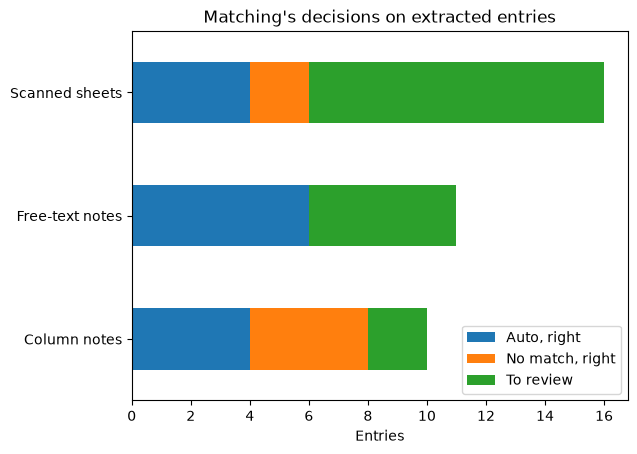

In [8]:
outcomes.plot.barh(stacked=True)
plt.xlabel("Entries")
plt.ylabel("")
plt.title("Matching's decisions on extracted entries")
plt.legend(title=None, loc="lower right")
plt.show()

In [9]:
checked[checked["outcome"] != "Auto, right"][["source", "entry", "client", "cmid", "narrative", "action", "pred_cmid",
                                                 "intended_cmid", "listed", "reason_short", "why"]]

,source,entry,client,cmid,narrative,action,pred_cmid,intended_cmid,listed,reason_short,why
0,2399_001.pdf,3,NaN,5520.001,lattend to matter.,NEEDS_REVIEW,5520.001,5520.001,True,Not sure enough to accept,HW-02: CMID written
2,2399_001.pdf,5,NaN,3012.001,Drft consulting agmt.,NEEDS_REVIEW,3012.001,3012.001,True,Not sure enough to accept,HW-02: CMID written
3,2399_001.pdf,8,NaN,4590.003,Attend to finacning mathers.,NEEDS_REVIEW,4590.003,4590.003,True,Not sure enough to accept,HW-03: CMID written as 4590-003
5,2399_001.pdf,11,Cobil t Ridge,5520.002,"nev. 3e, confi dential information memorandum ...",NEEDS_REVIEW,5520.002,5520.002,True,Not sure enough to accept,HW-01: CMID written sideways in the margin
6,2399_001.pdf,13,Daily Journal,NaN,respond to buyer DD request,NO_MATCH,NaN,NONE,False,Likely a new client or matter,HW-01: Daily Journal isn't a firm client
7,2399_001.pdf,14,Stand AI,NaN,truck Fund III investor Signature subsript,NEEDS_REVIEW,3388.001,NONE,False,No clear match,HW-01: Stand AI isn't a firm client
8,2399_001.pdf,15,Litera,NaN,Respond to LP Maning re Fund I distributions d...,NEEDS_REVIEW,8820.001,NONE,False,Not sure enough to accept,HW-01: Litera isn't a firm client
9,2399_001.pdf,16,Rat Bio -Series B,NaN,TCW M. white re new tax plan,NEEDS_REVIEW,4590.003,NONE,False,No clear match,HW-04: Rat Bio isn't a firm client
10,2399_001.pdf,17,Brave Capital-en,NaN,TOW A stone re amendments to LPA; make edits t...,NEEDS_REVIEW,9140.001,NONE,False,No clear match,HW-04: Brave Capital isn't a firm client
13,2399_001.pdf,20,Theories Fund 007,NaN,Attend to transfers of GP interest for Wang.,NO_MATCH,NaN,NONE,False,Likely a new client or matter,HW-04: Theories Fund isn't a firm client


- **No entry is matched automatically to the wrong matter** (0 of 37), including the 12 entries for clients or matters that aren't the firm's: 6 are marked as a new client and 6 are sent to review.
- 14 entries are matched to the intended matter with no review, including 6 of the 11 free-text note photos.
- In every review case with a firm matter intended, that matter is on the reviewer's shortlist except one: "Firm BD lunch w/ prospective client" leaned toward firm admin instead of business development.
- Written CMIDs still go to review when the narrative is vague ("attend to matter") or the timekeeper has never billed that matter. That's matching being careful, not an extraction problem.

## 5. Hours to confirm

Matching decides the matter and never looks at hours, so an entry can be matched automatically while its hours still need a quick confirmation (a decimal point Textract may have missed). This shows how often that happens.

In [10]:
results["confirm_hours"] = results["check_reasons"].fillna("").str.contains("|".join(HOURS_CHECKS))
pd.crosstab(results["action"], results["confirm_hours"].map({True: "Confirm hours", False: "Hours fine"}))

confirm_hours,Confirm hours,Hours fine
action,,
AUTO_MATCH,5,9
MULTI_MATTER,0,1
NEEDS_REVIEW,6,17
NO_MATCH,1,5


- 5 of the 14 automatic matches still have hours to confirm: decimal points Textract may have missed (HW-02's "3", HW-04's "2" and "6"), or hours it couldn't read at all (two notes).
- Since matching never looks at hours, these would be billed as read unless the app asks for a quick confirmation. That's a separate step from matter review, and it doesn't change matching's review rate.

## 6. Summary

The main numbers in one table, by input type:

| Column | Meaning |
|---|---|
| entries | entries extracted |
| no person | share decided with no person (matched, or marked as a new client) |
| to a person | share sent to review, flagged, or split across matters |
| auto right / auto wrong | automatic matches checked against the intended matter (known entries only) |
| on shortlist | when a firm matter was intended and the entry went to review, the share with that matter on the reviewer's shortlist |
| hours to confirm | automatic matches whose hours still need a quick confirmation |

In [11]:
def summary(group, known):
    to_person = ~group["action"].isin(["AUTO_MATCH", "NO_MATCH"])
    reviewed = known[(known["outcome"] == "To review") & (known["intended_cmid"] != "NONE")]
    return {
        "entries": len(group),
        "no person": 1 - to_person.mean(),
        "to a person": to_person.mean(),
        "auto right": (known["outcome"] == "Auto, right").sum(),
        "auto wrong": (known["outcome"] == "Auto, wrong").sum(),
        "on shortlist": reviewed["listed"].mean(),
        "hours to confirm": (group["confirm_hours"] & (group["action"] == "AUTO_MATCH")).sum(),
    }


inputs = ["Scanned sheets", "Column notes", "Free-text notes"]
metrics = {name: summary(results[results["input"] == name], checked[checked["input"] == name]) for name in inputs}
metrics["All"] = summary(results, checked)
pd.DataFrame.from_dict(metrics, orient="index").round(2)

,entries,no person,to a person,auto right,auto wrong,on shortlist,hours to confirm
Scanned sheets,23,0.26,0.74,4,0,1.00,3
Column notes,10,0.80,0.20,4,0,1.00,1
Free-text notes,11,0.55,0.45,6,0,0.80,1
All,44,0.45,0.55,14,0,0.91,5


- **No automatic match is wrong** for any input type.
- Notes with drawn columns are decided with no person most often (80%), then free-text notes (55%) and scanned sheets (26%).
- When an entry does go to review, the intended matter is on the shortlist 10 times out of 11.
- Overall, 45% of entries are decided with no person, against 71% on the synthetic TEST set.

## Findings

### Results
- **Runs as is:** every extracted entry, from scans, column notes, and photos, goes straight into `decide()`.
- **Safe:** 0 of 37 entries with a known intended matter were matched automatically to the wrong one.
- **Useful:** 20 of 44 entries decided with no person (14 matched, 6 new clients). The rest go to review, almost always with the right matter on the shortlist.
- **Hours:** 5 automatic matches still have hours to confirm, which matching can't catch on its own.

### Tradeoffs
- The entries go into matching exactly as extracted, misspellings included, so matching's own fuzzy matching does the interpreting. Correcting names during extraction would duplicate that and hide what was written.

### Limitations
- A small set of samples, and the free-text notes were written from the firm's client list for one timekeeper, so they're easier than real notes from unknown writers.
- The intended matter is only known for some sheet entries (written CMIDs, firm time, and clients that aren't the firm's).

### Next steps
- An app rule for entries matched automatically with hours to confirm.
- More real notes from other writers, then run them through this notebook.